In [12]:
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression,Ridge,Lasso,ElasticNet


In [2]:
california_house_data = fetch_california_housing()
california_house_data

{'data': array([[   8.3252    ,   41.        ,    6.98412698, ...,    2.55555556,
           37.88      , -122.23      ],
        [   8.3014    ,   21.        ,    6.23813708, ...,    2.10984183,
           37.86      , -122.22      ],
        [   7.2574    ,   52.        ,    8.28813559, ...,    2.80225989,
           37.85      , -122.24      ],
        ...,
        [   1.7       ,   17.        ,    5.20554273, ...,    2.3256351 ,
           39.43      , -121.22      ],
        [   1.8672    ,   18.        ,    5.32951289, ...,    2.12320917,
           39.43      , -121.32      ],
        [   2.3886    ,   16.        ,    5.25471698, ...,    2.61698113,
           39.37      , -121.24      ]], shape=(20640, 8)),
 'target': array([4.526, 3.585, 3.521, ..., 0.923, 0.847, 0.894], shape=(20640,)),
 'frame': None,
 'target_names': ['MedHouseVal'],
 'feature_names': ['MedInc',
  'HouseAge',
  'AveRooms',
  'AveBedrms',
  'Population',
  'AveOccup',
  'Latitude',
  'Longitude'],
 'DESCR': 

In [3]:
california_house_data

{'data': array([[   8.3252    ,   41.        ,    6.98412698, ...,    2.55555556,
           37.88      , -122.23      ],
        [   8.3014    ,   21.        ,    6.23813708, ...,    2.10984183,
           37.86      , -122.22      ],
        [   7.2574    ,   52.        ,    8.28813559, ...,    2.80225989,
           37.85      , -122.24      ],
        ...,
        [   1.7       ,   17.        ,    5.20554273, ...,    2.3256351 ,
           39.43      , -121.22      ],
        [   1.8672    ,   18.        ,    5.32951289, ...,    2.12320917,
           39.43      , -121.32      ],
        [   2.3886    ,   16.        ,    5.25471698, ...,    2.61698113,
           39.37      , -121.24      ]], shape=(20640, 8)),
 'target': array([4.526, 3.585, 3.521, ..., 0.923, 0.847, 0.894], shape=(20640,)),
 'frame': None,
 'target_names': ['MedHouseVal'],
 'feature_names': ['MedInc',
  'HouseAge',
  'AveRooms',
  'AveBedrms',
  'Population',
  'AveOccup',
  'Latitude',
  'Longitude'],
 'DESCR': 

In [4]:
california_house_data_df = pd.DataFrame(california_house_data.data,columns = california_house_data.feature_names)
california_house_data_df["Target"]=california_house_data.target
california_house_data_df


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Target
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
...,...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847


### data preparation

In [5]:
california_house_data_df.shape

(20640, 9)

In [9]:
california_house_data_df.isnull().sum()

MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
Target        0
dtype: int64

In [10]:
california_house_data_df.duplicated().sum()

np.int64(0)

In [11]:
california_house_data_df.dtypes

MedInc        float64
HouseAge      float64
AveRooms      float64
AveBedrms     float64
Population    float64
AveOccup      float64
Latitude      float64
Longitude     float64
Target        float64
dtype: object

### model building

In [6]:
X = california_house_data_df.head(350)
X

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Target
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
...,...,...,...,...,...,...,...,...,...
345,1.7120,36.0,6.307229,1.289157,651.0,3.921687,37.75,-122.18,0.821
346,2.5625,33.0,4.475524,1.073427,999.0,3.493007,37.76,-122.17,0.893
347,1.9821,43.0,5.186275,1.045752,907.0,2.964052,37.75,-122.17,0.983
348,2.5043,41.0,5.465217,1.178261,828.0,3.600000,37.75,-122.17,0.923


In [7]:
y=california_house_data_df["Target"][:350]
y

0      4.526
1      3.585
2      3.521
3      3.413
4      3.422
       ...  
345    0.821
346    0.893
347    0.983
348    0.923
349    0.888
Name: Target, Length: 350, dtype: float64

In [8]:
 X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=123,shuffle=True)

In [9]:
X_train.shape,y_train.shape


((280, 9), (280,))

In [10]:
X_test.shape,y_test.shape

((70, 9), (70,))

In [13]:
linear_model = LinearRegression()
ridge_model = Ridge(alpha=1.0)
lasso_model = Lasso(alpha=1.0)
elastic_net_model = ElasticNet(alpha=1.0)

### model training/testing/evaluation

In [14]:
linear_model.fit(X_train,y_train)
ridge_model.fit(X_train,y_train)
lasso_model.fit(X_train,y_train)
elastic_net_model.fit(X_train,y_train)

,alpha,1.0
,l1_ratio,0.5
,fit_intercept,True
,precompute,False
,max_iter,1000
,copy_X,True
,tol,0.0001
,warm_start,False
,positive,False
,random_state,None
,selection,'cyclic'


In [16]:
print("Linear Regression Coefficients")
print(linear_model.coef_)

print("Ridge Regression Coefficients")
print(ridge_model.coef_)

print("Lasso Regression Coefficients")
print(lasso_model.coef_)

print("Elastic Net Coefficients")
print(elastic_net_model.coef_)

Linear Regression Coefficients
[ 2.31589102e-16 -1.24900090e-16 -9.22439208e-16 -3.55614247e-15
  2.77555756e-17 -3.43149988e-16  5.08217735e-15  9.23591173e-16
  1.00000000e+00]
Ridge Regression Coefficients
[ 4.89296936e-03 -3.95294537e-05 -4.63171847e-04 -1.03109490e-02
  1.24184120e-06 -1.55990569e-03  1.66982600e-02 -1.44153124e-02
  9.87516550e-01]
Lasso Regression Coefficients
[ 9.34434033e-02 -0.00000000e+00  0.00000000e+00 -0.00000000e+00
  9.82399743e-05 -0.00000000e+00  0.00000000e+00 -0.00000000e+00
  0.00000000e+00]
Elastic Net Coefficients
[ 1.85855353e-01 -0.00000000e+00  0.00000000e+00 -0.00000000e+00
  1.00021637e-04 -0.00000000e+00  0.00000000e+00 -0.00000000e+00
  8.11327534e-02]


      Feature   Coefficient
3   AveBedrms -3.556142e-15
2    AveRooms -9.224392e-16
5    AveOccup -3.431500e-16
1    HouseAge -1.249001e-16
4  Population  2.775558e-17
0      MedInc  2.315891e-16
7   Longitude  9.235912e-16
6    Latitude  5.082177e-15
8      Target  1.000000e+00


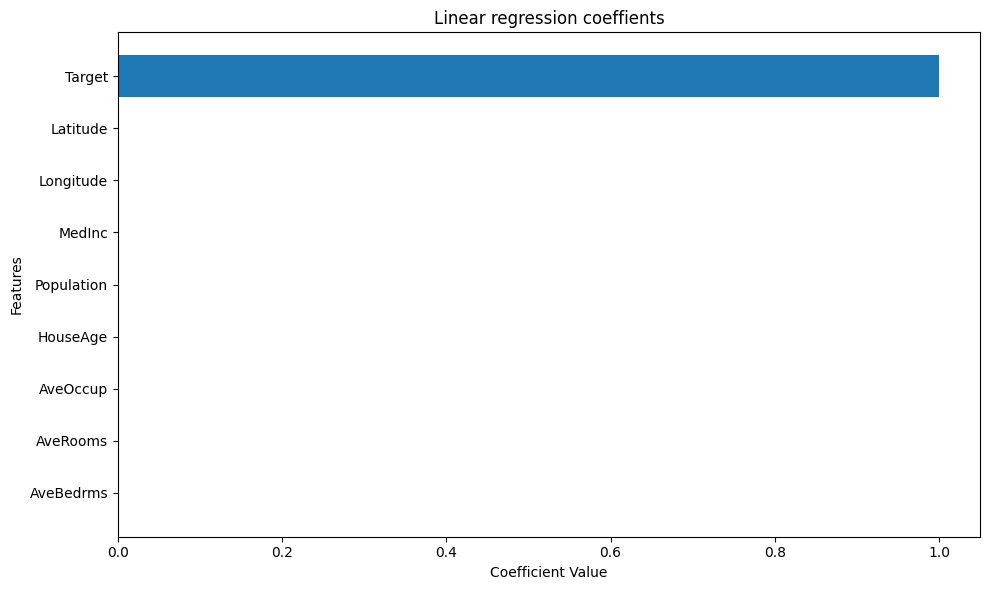

      Feature  Coefficient
7   Longitude    -0.014415
3   AveBedrms    -0.010311
5    AveOccup    -0.001560
2    AveRooms    -0.000463
1    HouseAge    -0.000040
4  Population     0.000001
0      MedInc     0.004893
6    Latitude     0.016698
8      Target     0.987517


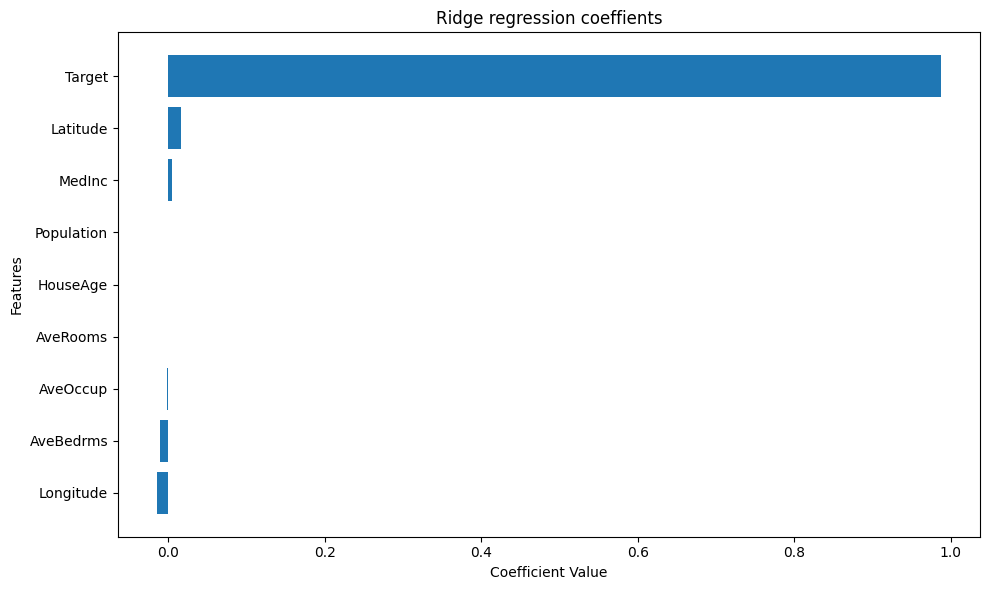

      Feature  Coefficient
1    HouseAge    -0.000000
2    AveRooms     0.000000
3   AveBedrms    -0.000000
5    AveOccup    -0.000000
7   Longitude    -0.000000
6    Latitude     0.000000
8      Target     0.000000
4  Population     0.000098
0      MedInc     0.093443


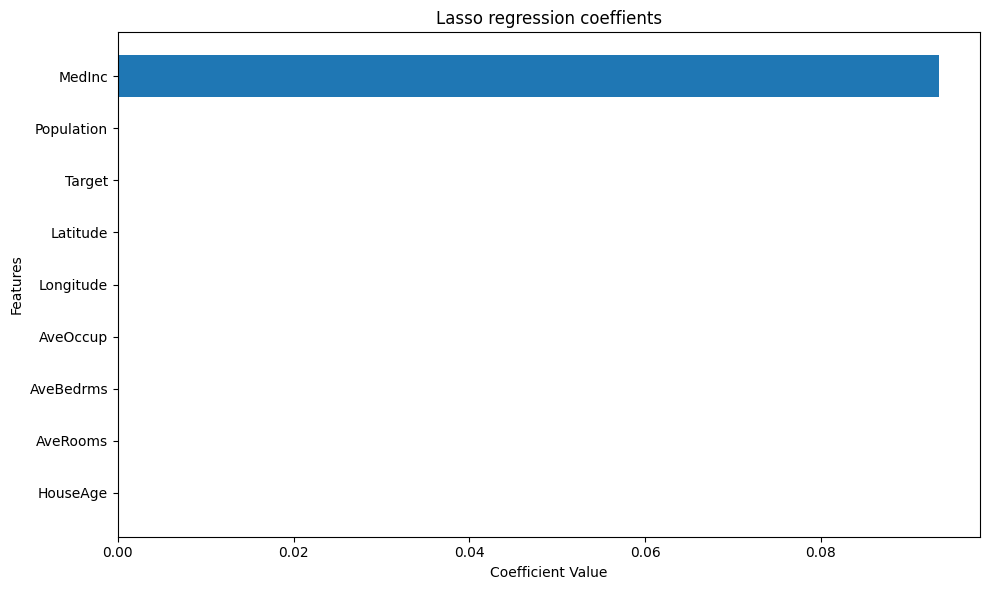

      Feature  Coefficient
1    HouseAge    -0.000000
2    AveRooms     0.000000
3   AveBedrms    -0.000000
5    AveOccup    -0.000000
7   Longitude    -0.000000
6    Latitude     0.000000
4  Population     0.000100
8      Target     0.081133
0      MedInc     0.185855


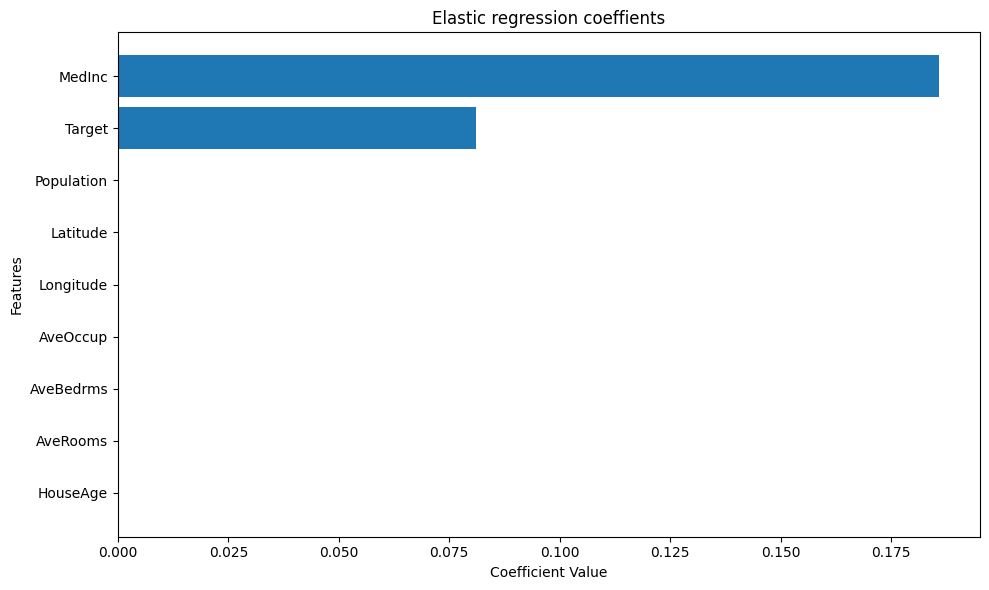

In [29]:
from matplotlib import pyplot as plt
def plot_coefficients(model,feature_names,title):
    coef_df = pd.DataFrame({
        "Feature": feature_names,
        "Coefficient": model.coef_
    })
    coef_df = coef_df.sort_values(by="Coefficient")
    print(coef_df)
    plt.figure(figsize=(10,6))
    plt.barh(coef_df["Feature"], coef_df["Coefficient"])
    
    plt.title(title)
    plt.xlabel("Coefficient Value")
    plt.ylabel("Features")
    
    plt.tight_layout()
    plt.show()
        



plot_coefficients(
    linear_model,
    X.columns,
    "Linear regression coeffients"
)
plot_coefficients(
    ridge_model,
    X.columns,
    "Ridge regression coeffients"
)
plot_coefficients(
    lasso_model,
    X.columns,
    "Lasso regression coeffients"
)
plot_coefficients(
    elastic_net_model,
    X.columns,
    "Elastic regression coeffients"
)

In [27]:
print(coef_df)

NameError: name 'coef_df' is not defined

In [26]:
coef_df

NameError: name 'coef_df' is not defined

In [31]:
from sklearn.metrics import mean_squared_error, r2_score

models = {
    "Linear": linear_model,
    "Ridge": ridge_model,
    "Lasso": lasso_model,
    "ElasticNet": elastic_net_model
}

for name, model in models.items():
    
    y_pred = model.predict(X_test)
    
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    
    print(name)
    print("MSE:", mse)
    print("R2:", r2)
    print()

Linear
MSE: 2.357412207639841e-28
R2: 1.0

Ridge
MSE: 3.1896748823837614e-05
R2: 0.9999462787267079

Lasso
MSE: 0.4699027592633154
R2: 0.2085784450789251

ElasticNet
MSE: 0.2852382360288927
R2: 0.5195948867488289



In [32]:
models.items()

dict_items([('Linear', LinearRegression()), ('Ridge', Ridge()), ('Lasso', Lasso()), ('ElasticNet', ElasticNet())])

In [33]:
model.coef_

array([ 1.85855353e-01, -0.00000000e+00,  0.00000000e+00, -0.00000000e+00,
        1.00021637e-04, -0.00000000e+00,  0.00000000e+00, -0.00000000e+00,
        8.11327534e-02])